# Qualidade em Engenharia de Machine Learning e IA

Em desenvolvimento de software, conhecer e aplicar técnicas para a melhoria da qualidade dos produtos digitais é essencial para uma entrega em nível profissional. Muitas técnicas e disciplinas são discutidas por desenvolvedores, engenheiros de software e de qualidade, como TDD (Test-Drive Developmen), BDD (Behavior-Driven Development) , entre outras.

Quando lidamos com produtos que utilizam algoritmos de *machine learning* ou IA para atividades críticas na indústria, na educação e até mesmo em um simples chat, a qualidade se torna ainda mais necessária.

Há uma mudança essencial quando discutimos testes de qualidade para ML/IA: essa mudança está em como devemos olhar para essa tarefa e quais são os fundamentos e paradigmas que afetam o planejamento e a visão do engenheiro.

Por um lado, na engenharia tradicional, os casos de teste são determinísticos — ou seja, independentemente do número de vezes que testarmos, as respostas serão sempre as mesmas para as mesmas entradas de dados, caso a função ou funcionalidade não mude (dado um valor de entrada X, sempre recebo Y como resposta).

No caso dos algoritmos de *machine learning* e de outras especialidades de inteligência artificial, sempre temos uma resposta probabilística. Por isso, não testamos o que devemos receber como resposta, e sim o quão próxima essa resposta está da realidade que estamos testando — e, mais ainda, quais são os limites de tolerância que temos como margem de erro.

## O Triângulo de "Falha" em ML

Quando uma predição de um modelo dá errado em produção, devemos avaliar três possíveis fontes do erro:

1. **Código da pipeline de dados**
2. **Qualidade dos dados**
3. **O modelo**

O código da pipeline é um dos três aspectos essenciais para a qualidade e o sucesso dos projetos de ML/IA. A etapa de busca, armazenamento e tratamento dos dados é o que garante a qualidade dos dados utilizados para o aprendizado e a análise, assegurando a saúde do produto/serviço.

A qualidade dos dados se refere a alguns fatores, como:

- Perda de dados
- Valores ausentes
- Ruídos fora das especificações
- Problemas de desalinhamento temporal

O modelo em si pode apresentar problemas como:

- Calibração ruim
- Degradação por mudança do ambiente analisado
- Perda de *recall* em classes raras

## Objetivo do Trabalho

O intuito deste trabalho é analisar a visão de engenharia de qualidade de ML utilizando um exemplo prático, entender para onde e para o que devemos olhar quando se trata de testes dentro desse paradigma, e verificar o resultado da aplicação das técnicas utilizadas nesse exemplo.

> Todas as informações do projeto de estudo podem ser encontradas no repositório: [github.com/felipehp/sentinela-nortemec](https://github.com/felipehp/sentinela-nortemec)

## Preparação do Ambiente

Nesta etapa, realizamos a preparação do ambiente de trabalho no Google Colab, necessária para a execução prática dos testes de qualidade em ML/IA propostos neste estudo.

O processo consiste em três etapas principais:

1. **clone do projeto no Colab**, garantindo que o projeto de estudo fornecido esteja disponível para a execução dos scripts e do modelo.
2. **Importação do projeto** para o ambiente de código, permitindo o acesso direto às classes, funções e módulos que serão utilizados ao longo dos testes.
3. **Criação do diretório de testes**, onde serão armazenados os scripts responsáveis pela validação da pipeline de dados, da qualidade dos dados e do modelo, conforme discutido no Triângulo de Falha em ML.

In [3]:

!git clone https://github.com/felipehp/sentinela-nortemec.git sentinela
%cd sentinela
!pip install -e . -q
!pip install pytest scikit-learn scipy -q

# Verificar se o pacote carrega corretamente
import sentinela as sn
print("Pacote Sentinela instalado com sucesso!")

Cloning into 'sentinela'...
remote: Enumerating objects: 31, done.
remote: Counting objects: 100% (31/31), done.
remote: Compressing objects: 100% (27/27), done.
remote: Total 31 (delta 0), reused 31 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (31/31), 732.09 KiB | 4.52 MiB/s, done.
/content/sentinela
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for sentinela (pyproject.toml) ... done
Pacote Sentinela instalado com sucesso!


In [4]:
import os
os.makedirs("tests", exist_ok=True)
print("Diretório tests/ criado.")

Diretório tests/ criado.


# Testes Unitários do Pipeline (`test_01_pipeline.py`)

Conhecendo o "Triângulo de Falhas" que discutimos anteriormente, podemos olhar para dois aspectos que influenciam o planejamento e a execução dos testes de pipeline de dados.

No caso em que os testes necessitam apenas dos resultados probabilísticos, podemos enxergar principalmente o **contrato dos dados** que nossas funções recebem, para que consigamos validar os parâmetros de entrada em sua estrutura e natureza, como tipos e estruturas de dados. A mudança de mentalidade de um engenheiro que lida com ML está em enxergar e avaliar como as qualidades físicas desses dados influenciam na qualidade e na saúde do projeto.

## Qualidades Físicas dos Dados

Os dados representam aspectos físicos do ambiente analisado pelo projeto sob teste (Sentinela).
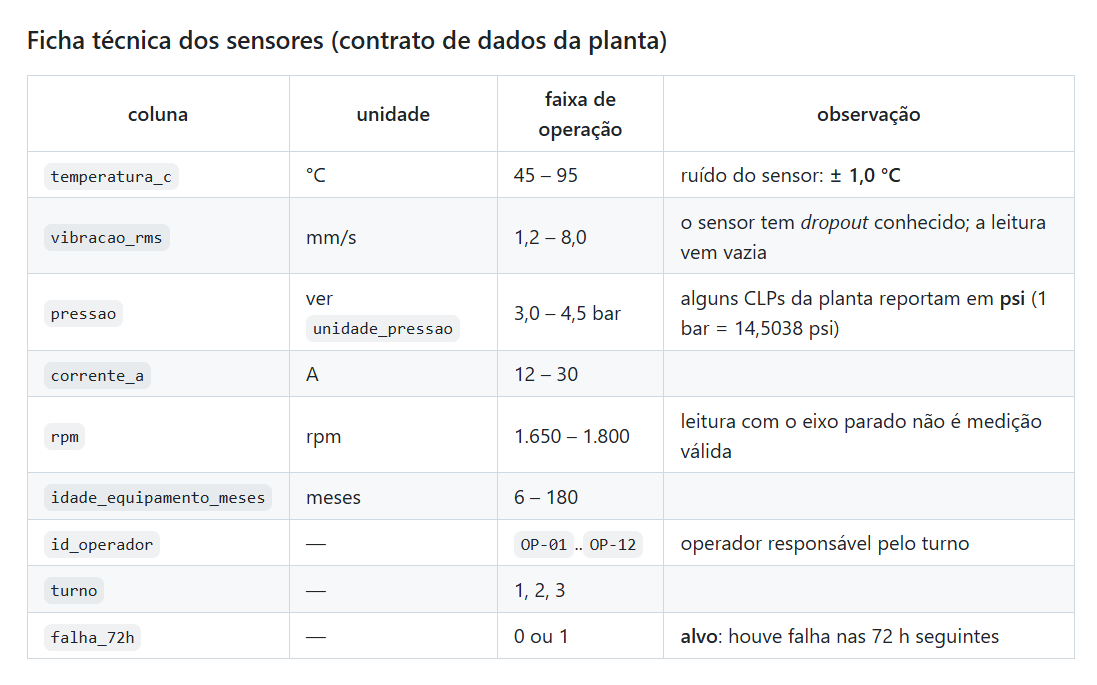

A qualidade e a análise correta dos dados irão garantir que o modelo realize predições mais precisas e corretas.

1. **Unidade de medida**
   Segundo a ficha técnica dos sensores, a unidade correta para os dados de pressão é "Bar".

2. **Limites operacionais dos dados**
   A especificação informa as faixas operacionais de temperatura e corrente elétrica.

3. **Integridade temporal (*Leakage temporal*)**
   Os dados devem garantir que as *features* não sejam afetadas por alterações ou pela utilização de dados do futuro.

4. **Dados faltantes**
   Testar dados faltantes e validar como o sistema lida com a perda ou o não recebimento de dados.

Os testes unitários de pipeline devem garantir que esses dados estejam de acordo com as propriedades físicas sinalizadas pela especificação da ficha técnica dos sensores, bem como com sua integridade.


In [16]:
%%writefile tests/test_01_pipeline.py
import pytest
import numpy as np
import pandas as pd
import sentinela as sn

@pytest.fixture
def dados_brutos():
    return sn.dados.carregar("treino")

# 1. Teste de Unidade de Pressão
def test_unidade_pressao_conversao(dados_brutos):
    """Verifica se leituras registradas em psi são convertidas corretamente para bar."""
    df_limpo = sn.preprocessamento.limpar(dados_brutos.copy())

    # Registros onde a unidade original era psi
    if "unidade_pressao" in dados_brutos.columns:
        linhas_psi = dados_brutos["unidade_pressao"] == "psi"
        if linhas_psi.any():
            pressao_original_psi = dados_brutos.loc[linhas_psi, "pressao"]
            pressao_limpa = df_limpo.loc[linhas_psi, "pressao"]

            # A pressão limpa deve estar na faixa de 3.0 a 4.5 bar
            assert (pressao_limpa <= 5.0).all(), "Existem valores de pressão acima de 5.0"

# 2. Teste de Faixa dos Sensores (Valores Outliers / Ficha Técnica)
def test_faixa_operacional_sensores(dados_brutos):
    """Verifica se os dados preprocessados respeitam os limites operacionais das especificações técnicas."""
    df_limpo = sn.preprocessamento.limpar(dados_brutos.copy())

    # Temperatura: 45 - 95 °C
    assert df_limpo["temperatura_c"].min() >= 40.0, "Temperatura abaixo da faixa mínima aceitável"
    assert df_limpo["temperatura_c"].max() <= 100.0, "Temperatura acima da faixa máxima aceitável"

    # Corrente: 12 - 30 A
    assert df_limpo["corrente_a"].min() >= 10.0, "Corrente abaixo do limite operacional"
    assert df_limpo["corrente_a"].max() <= 35.0, "Corrente acima do limite operacional"

# 3. Teste de Valores Faltantes (Dropout de sensor)
def test_tratamento_valores_faltantes(dados_brutos):
    df_limpo = sn.preprocessamento.limpar(dados_brutos.copy())
    assert df_limpo.isna().sum().sum() == 0, "Existem valores faltantes"

# 4. Teste de RPM Zerado (Eixo Parado)
def test_rpm_eixo_parado(dados_brutos):
    df_limpo = sn.preprocessamento.limpar(dados_brutos.copy())
    assert (df_limpo["rpm"] > 0).all(), "Existem RPMs zerados"

# 5. Teste de Data Leakage (Vazamento Temporal na Construção de Features)
def test_vazamento_temporal_features():
    bruto = sn.dados.carregar("teste")
    df_limpo = sn.preprocessamento.limpar(bruto.copy())

    # Seleciona 1 motor e altera drasticamente uma leitura no futuro
    id_maquina = df_limpo["id_maquina"].iloc[0]
    df_motor = df_limpo[df_limpo["id_maquina"] == id_maquina].copy().sort_values("timestamp")

    # Construção de features original
    X_orig = sn.features.construir(df_motor)

    # Altera os dados das últimas linhas (futuro)
    df_motor_modificado = df_motor.copy()
    df_motor_modificado.iloc[-1, df_motor_modificado.columns.get_loc("temperatura_c")] += 50.0

    X_mod = sn.features.construir(df_motor_modificado)

    assert np.allclose(X_orig.iloc[0].values, X_mod.iloc[0].values), "Vazamento temporal na construção de features"

Overwriting tests/test_01_pipeline.py


#Testes Estatísticos (`test_02_estatisticos.py`)

Em software tradicional, se um teste unitário passa uma vez, ele passará sempre (desde que o código e as entradas não mudem). Em ML, testar se "o modelo acertou a predição da amostra X" não prova nada sobre a qualidade real do sistema.

Precisamos de testes de hipótese estatísticos e medidas de incerteza.

## Método Bootstrap
Quando avaliamos o modelo v1 no conjunto de teste e descobrimos que o Recall foi de **94,2%**, esse número é apenas uma estimativa pontual. Ele depende estritamente das amostras específicas que estavam naquele conjunto de dados. Se você coletasse outro lote de testes com 1.000 amostras na semana seguinte, o Recall poderia ser **91%** ou **96%**.

A pergunta de qualidade que um engenheiro deve fazer é: **"Qual é a margem de incerteza dessa métrica?"**

Como não podemos viajar no tempo e coletar infinitos dados reais para testar o modelo, usamos o **Bootstrap** (reamostragem com reposição):

1. Pegamos nosso conjunto de teste com **N** amostras.
2. Sorteamos aleatoriamente **N** amostras desse conjunto com reposição (uma mesma amostra pode ser sorteada mais de uma vez).
3. Calculamos o Recall nessa "nova" base sorteada.
4. Repetimos esse processo 300 ou 1.000 vezes.
5. No final, teremos 300 (ou 1.000) valores de Recall. Pegamos os percentis **2,5%** e **97,5%** para formar o Intervalo de Confiança de 95% (IC 95%).

```
# Resultado da execução do Bootstrap 95%:
Recall v1: [0.9242, 0.9615]  # Varia de 92,4% a 96,1%
Recall v2: [0.7834, 0.8419]  # Varia de 78,3% a 84,1%
```

Como os dois intervalos de confiança não se sobrepõem (**0,8419 < 0,9242**), temos 95% de certeza estatística de que a degradação de Recall do modelo v2 não foi um mero azar na amostragem dos dados de teste. A v2 é, portanto, comprovadamente inferior para a detecção de falhas.

## Teste Estatístico de McNemar

Diferente do Bootstrap, o teste de McNemar não olha para a pontuação geral de cada modelo; ele foca exclusivamente nos **erros discordantes** entre os dois modelos — ou seja, os casos em que um modelo acerta e o outro erra.

O método verifica se essas discordâncias são estatisticamente significativas, ou se poderiam ter surgido por acaso, dada a amostra específica de dados utilizada nos testes. Ele é especialmente útil quando os intervalos de confiança do Bootstrap se sobrepõem e não fica claro se existe, de fato, uma diferença real de desempenho entre as duas versões — nesses casos, o teste de McNemar pode revelar estatisticamente uma discordância que a comparação simples de métricas não deixa evidente.

A estatística de teste do McNemar é calculada por:

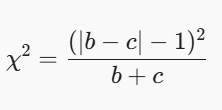

Se o valor resultante dessa estatística for menor que **0,05** isso prova que os diferencas de resultados não foram por mero acaso. Para o nosso exemplo, isso revela que o nosso modelo v2 é muito provavelmente inferior ao v1

In [8]:
%%writefile tests/test_02_estatisticos.py
import pytest
import numpy as np
import pandas as pd
from scipy import stats
import sentinela as sn

@pytest.fixture
def dados_teste():
    return sn.dados.carregar("teste")

@pytest.fixture
def dados_producao():
    return sn.dados.carregar("producao")

# 1. Teste de Desempenho em Classe Rara (v1 vs v2)
def test_v2_recall_classe_rara(dados_teste):
    """Garante que o novo modelo v2 não degrade o Recall para a classe minoritária (falhas)."""
    saida_v1 = sn.pipeline.executar(dados_teste.copy(), versao="v1")
    saida_v2 = sn.pipeline.executar(dados_teste.copy(), versao="v2")

    y_real = saida_v1["falha_72h"]
    m_v1 = sn.avaliacao.metricas(y_real, saida_v1["predicao"])
    m_v2 = sn.avaliacao.metricas(y_real, saida_v2["predicao"])

    recall_v1 = m_v1.get("recall", 0.0)
    recall_v2 = m_v2.get("recall", 0.0)

    assert recall_v2 >= recall_v1, (
        f"Recall v1: {recall_v1:.4f} | Recall v2: {recall_v2:.4f}"
    )

# 2. Teste Estatístico de McNemar (Significância v1 vs v2)
def test_mcnemar_v1_vs_v2(dados_teste):
    """Verifica se a diferença de predições entre v1 e v2 é estatisticamente significativa."""
    saida_v1 = sn.pipeline.executar(dados_teste.copy(), versao="v1")
    saida_v2 = sn.pipeline.executar(dados_teste.copy(), versao="v2")

    y_real = saida_v1["falha_72h"].values
    pred_v1 = saida_v1["predicao"].values
    pred_v2 = saida_v2["predicao"].values

    correto_v1 = (pred_v1 == y_real)
    correto_v2 = (pred_v2 == y_real)

    # Tabela de contingência para McNemar:
    # b: v1 acertou e v2 errou
    # c: v1 errou e v2 acertou
    b = np.sum(correto_v1 & ~correto_v2)
    c = np.sum(~correto_v1 & correto_v2)

    # Estatística do teste de McNemar com correção de continuidade
    if (b + c) > 0:
        chi2 = (abs(b - c) - 1)**2 / (b + c)
        p_valor = stats.chi2.sf(chi2, df=1)
    else:
        p_valor = 1.0

    print(f"\n[McNemar] Discordâncias -> v1_certa/v2_errada: {b}, v1_errada/v2_certa: {c} | p-value: {p_valor:.5f}")
    assert p_valor < 0.05, f"A diferença entre v1 e v2 NÃO é estatisticamente significativa (p={p_valor:.4f})"

# 3. Teste de Distribution Drift / Kolmogorov-Smirnov (Teste vs Produção)
def test_data_drift_producao(dados_teste, dados_producao):
    """Compara as distribuições dos dados entre o lote de Teste e o de Produção."""
    limpo_teste = sn.preprocessamento.limpar(dados_teste.copy())
    limpo_prod = sn.preprocessamento.limpar(dados_producao.copy())

    colunas_continuas = ["temperatura_c", "vibracao_rms", "corrente_a", "rpm"]

    drift_detectado = []
    for col in colunas_continuas:
        ks_stat, p_value = stats.ks_2samp(limpo_teste[col].dropna(), limpo_prod[col].dropna())
        if p_value < 0.01:
            drift_detectado.append((col, p_value))

    assert len(drift_detectado) == 0, f"Data Drift detectado entre Teste e Produção nas colunas: {drift_detectado}"

Writing tests/test_02_estatisticos.py


# Robustez, Testes Adversariais e Casos-Limite (`test_03_adversariais.py`)

Além de validar o contrato e a qualidade física dos dados, um engenheiro de qualidade em ML precisa avaliar como o **modelo se comporta** diante de variações nos dados de entrada. Diferente dos testes de acurácia ou Recall, que medem *o quão certo* o modelo está, esses testes medem *o quão consistente e confiável* é o comportamento do modelo diante de mudanças que, do ponto de vista do domínio, não deveriam (ou não deveriam significativamente) alterar sua decisão.

Dois conceitos guiam essa análise: **invariância** (o modelo não deve reagir a variáveis irrelevantes para o problema) e **robustez** (o modelo não deve reagir de forma desproporcional a ruídos pequenos, dentro da margem de erro esperada dos sensores).

##Teste Contrafactual

Um teste contrafactual avalia o modelo perguntando: **"Se eu alterar apenas uma variável que não deveria influenciar a decisão, o resultado muda?"** Essa técnica é amplamente utilizada para detectar dependências indevidas do modelo em relação a atributos que são irrelevantes — ou, em contextos mais sensíveis, discriminatórios — para a predição.

No caso do Sentinela, `id_operador` e `turno` são metadados operacionais: identificam *quem* e *quando* a leitura foi registrada, mas não representam nenhuma propriedade física do equipamento monitorado. Um modelo bem calibrado não deveria associar a probabilidade de falha ao operador responsável ou ao turno de trabalho — caso contrário, isso indicaria **vazamento de viés operacional** (por exemplo, o modelo "aprendeu" que falhas são mais reportadas no turno da noite, em vez de aprender os sinais físicos que realmente antecedem uma falha).

O teste funciona da seguinte forma:

1. Executa a pipeline com os dados originais e registra a probabilidade de falha prevista (`proba_orig`).
2. Cria uma cópia dos dados, fixando `id_operador` em um valor único (`"OP-99"`) e `turno` em um valor único (`3`) para todas as linhas.
3. Executa a pipeline novamente sobre os dados alterados (`proba_mod`).
4. Compara a maior diferença absoluta entre as duas saídas (`diff_max`).

A asserção exige que essa diferença seja menor que `1e-3` — um limiar próximo de zero, já que, teoricamente, essas variáveis não deveriam ter nenhum peso relevante na decisão do modelo. Se o teste falhar, é um forte indício de que o modelo está utilizando metadados como *proxy* indevido para prever falhas, em vez de se basear nas variáveis físicas do equipamento.

##Teste de Robustez a Ruído Abaixo da Precisão do Sensor

Todo sensor físico possui uma margem de erro de medição inerente. Se a ficha técnica do sensor de temperatura indica uma precisão de, por exemplo, ±0,5°C, isso significa que duas leituras "reais" idênticas podem chegar ao sistema com valores ligeiramente diferentes — sem que isso represente, de fato, uma mudança no estado físico do equipamento.

A teoria por trás desse teste é a de que **um modelo robusto não deve mudar sua decisão binária apenas por causa de uma variação que está dentro da margem de erro do próprio instrumento de medição**. Se pequenas flutuações de ruído — que não carregam informação real sobre o ambiente — forem suficientes para alterar a predição, o modelo está *overfitado* a ruído, e não às tendências reais dos dados, tornando-se instável em produção.

O teste funciona da seguinte forma:

1. Executa a pipeline com os dados originais e registra a decisão binária do modelo (`pred_orig`).
2. Gera um ruído aleatório uniforme no intervalo `[-0.5, 0.5]` (compatível com a precisão declarada do sensor) e o soma à coluna `temperatura_c`.
3. Executa a pipeline novamente sobre os dados com ruído (`pred_ruido`).
4. Calcula a **taxa de mudança de decisão** (`mudancas`), ou seja, a proporção de amostras cuja predição binária mudou apenas devido ao ruído.

A asserção exige que menos de **2%** das decisões mudem. Esse limiar reconhece que uma pequena instabilidade é esperada — o modelo não precisa ser absolutamente imune a qualquer ruído —, mas estabelece uma tolerância que separa um comportamento aceitável de um modelo genuinamente frágil, cuja fronteira de decisão é sensível demais a variações irrelevantes do ponto de vista físico.

In [9]:
%%writefile tests/test_03_adversariais.py
import pytest
import numpy as np
import pandas as pd
import sentinela as sn

@pytest.fixture
def dados_teste():
    return sn.dados.carregar("teste")

# 1. Teste Contrafactual: id_operador e turno não devem alterar a decisão do modelo
def test_contrafactual_operador_turno(dados_teste):
    bruto_orig = dados_teste.copy()

    # Execução original
    saida_orig = sn.pipeline.executar(bruto_orig, versao="v1")
    proba_orig = saida_orig["probabilidade"].values

    # Alterando id_operador para um valor fixo em todas as linhas
    bruto_mod = bruto_orig.copy()
    bruto_mod["id_operador"] = "OP-99"
    bruto_mod["turno"] = 3

    saida_mod = sn.pipeline.executar(bruto_mod, versao="v1")
    proba_mod = saida_mod["probabilidade"].values

    diff_max = np.max(np.abs(proba_orig - proba_mod))
    assert diff_max < 1e-3, f"Falha Contrafactual: Alterar operador/turno mudou a probabilidade de falha em até {diff_max:.4f}"

# 2. Teste de Robustez a Ruído Menor que a Precisão do Sensor
def test_sensibilidade_ruido_temperatura(dados_teste):
    bruto_orig = dados_teste.copy()

    saida_orig = sn.pipeline.executar(bruto_orig, versao="v1")
    pred_orig = saida_orig["predicao"].values

    # Adiciona ruído uniforme em [-0.5, 0.5] na temperatura
    np.random.seed(42)
    bruto_ruido = bruto_orig.copy()
    ruido = np.random.uniform(-0.5, 0.5, size=len(bruto_ruido))
    bruto_ruido["temperatura_c"] = bruto_ruido["temperatura_c"] + ruido

    saida_ruido = sn.pipeline.executar(bruto_ruido, versao="v1")
    pred_ruido = saida_ruido["predicao"].values

    # Calcula a taxa de variação na decisão binária
    mudancas = np.mean(pred_orig != pred_ruido)

    # Espera-se que menos de 2% das decisões mudem devido a um ruído menor que a tolerância do sensor
    assert mudancas < 0.02, f"Modelo altamente instável! Ruído de ±0.5°C alterou {mudancas*100:.2f}% das decisões do modelo."

Writing tests/test_03_adversariais.py


In [17]:
# Executar a suíte de testes completa
!pytest tests/ -v

============================= test session starts ==============================
platform linux -- Python 3.13.15, pytest-8.4.2, pluggy-1.6.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/sentinela
configfile: pyproject.toml
plugins: langsmith-0.12.1, anyio-4.14.2, typeguard-4.6.0
collected 10 items                                                             

tests/test_01_pipeline.py::test_unidade_pressao_conversao FAILED         [ 10%]
tests/test_01_pipeline.py::test_faixa_operacional_sensores PASSED        [ 20%]
tests/test_01_pipeline.py::test_tratamento_valores_faltantes PASSED      [ 30%]
tests/test_01_pipeline.py::test_rpm_eixo_parado PASSED                   [ 40%]
tests/test_01_pipeline.py::test_vazamento_temporal_features PASSED       [ 50%]
tests/test_02_estatisticos.py::test_v2_recall_classe_rara FAILED         [ 60%]
tests/test_02_estatisticos.py::test_mcnemar_v1_vs_v2 PASSED              [ 70%]
tests/test_02_estatisticos.py::test_data_drift_producao FAILE

In [18]:
# Gerar log oficial de execução para a entrega
!pytest tests/ -v -s > relatorio_execucao_testes.txt
!cat relatorio_execucao_testes.txt

============================= test session starts ==============================
platform linux -- Python 3.13.15, pytest-8.4.2, pluggy-1.6.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/sentinela
configfile: pyproject.toml
plugins: langsmith-0.12.1, anyio-4.14.2, typeguard-4.6.0
collecting ... collected 10 items

tests/test_01_pipeline.py::test_unidade_pressao_conversao FAILED
tests/test_01_pipeline.py::test_faixa_operacional_sensores PASSED
tests/test_01_pipeline.py::test_tratamento_valores_faltantes PASSED
tests/test_01_pipeline.py::test_rpm_eixo_parado PASSED
tests/test_01_pipeline.py::test_vazamento_temporal_features PASSED
tests/test_02_estatisticos.py::test_v2_recall_classe_rara FAILED
tests/test_02_estatisticos.py::test_mcnemar_v1_vs_v2 
[McNemar] Discordâncias -> v1_certa/v2_errada: 92, v1_errada/v2_certa: 238 | p-value: 0.00000
PASSED
tests/test_02_estatisticos.py::test_data_drift_producao FAILED
tests/test_03_adversariais.py::test_contrafactual_operador_turn

# Relatório de Execução dos Testes (`pytest`)

## Sumário da Execução

A suíte de testes do projeto **Sentinela** foi executada com um total de **10 casos de teste**, distribuídos em três arquivos, refletindo as três camadas discutidas ao longo deste trabalho: pipeline de dados, testes estatísticos e testes adversariais/comportamentais do modelo.

| Resultado | Quantidade |
|---|---|
| ✅ Passou | 6 |
| ❌ Falhou | 4 |
| **Total** | **10** |

A seguir, cada falha é analisada com base no **Triângulo de Falha em ML** apresentado anteriormente (código de pipeline, qualidade dos dados e modelo), relacionando o resultado obtido com a teoria que fundamentou o desenho de cada teste.

---

## 1. Falhas no Código da Pipeline

### `test_unidade_pressao_conversao` — **FALHOU**

Este teste valida o **contrato físico dos dados**: registros originalmente medidos em *psi* devem ser convertidos para *bar* durante o pré-processamento, respeitando a faixa operacional esperada (até 5.0 bar).

A execução mostrou que, após a limpeza, os valores de pressão permaneceram na casa de **49 a 61**, ou seja, na mesma ordem de grandeza dos dados originais em *psi* — o que indica que a conversão de unidade **não foi aplicada** pela função `sn.preprocessamento.limpar`. Esse é um exemplo direto de falha no **código de pipeline**: não se trata de um problema do modelo ou da qualidade intrínseca do dado coletado pelo sensor, mas sim de uma etapa de transformação ausente. Sem essa correção, o modelo passaria a "enxergar" pressões fora de qualquer faixa fisicamente plausível, comprometendo qualquer predição futura.

---

## 2. Falhas de Qualidade e Comportamento dos Dados

### `test_data_drift_producao` — **FALHOU**

Este teste aplica o **teste de Kolmogorov-Smirnov (KS)** para comparar a distribuição de cada variável contínua (`temperatura_c`, `vibracao_rms`, `corrente_a`, `rpm`) entre o lote de teste e o lote de produção mais recente. A teoria por trás desse teste é que um modelo treinado assume implicitamente que os dados futuros seguirão a mesma distribuição dos dados de treino/teste (hipótese de *dados i.i.d.*); quando essa hipótese é violada, chamamos esse comportamento de **data drift**.

O resultado mostrou valore muito abaixo do limiar de significância de 0.01 adotado. Isso indica, que a distribuição dos dados de produção **mudou** em relação ao conjunto de teste original. Esse resultado se relaciona diretamente tópico  **qualidade dos dados** do Triângulo de Falha, especificamente ao problema de **degradação por mudança de ambiente**


## 3. Falhas do Modelo

### `test_v2_recall_classe_rara` — **FALHOU**

Este teste garante que uma nova versão do modelo (v2) não degrade o Recall para a classe minoritária ou classe rara — no caso, as falhas reais de equipamento (`falha_72h = 1`), que é justamente a classe que o sistema existe para detectar.

O resultado mostrou uma queda relevante: **Recall v1 = 94,20%** contra **Recall v2 = 81,37%**, uma perda de quase 13 pontos percentuais. Isso caracteriza diretamente o tópico **o modelo** do Triângulo de Falha, no problema específico de **perda de Recall em classes raras**, discutido anteriormente como um risco típico de **desbalanceamento de classes**. Na prática, isso significa que o modelo v2, mesmo que possa ter melhorado em outras métricas, está deixando passar despercebidas mais falhas reais — um retrocesso crítico para um sistema de manutenção preditiva, cujo custo de um falso negativo (não detectar uma falha) tende a ser muito maior que o de um falso positivo.

Esse resultado é reforçado estatísticamente pelo teste `test_mcnemar_v1_vs_v2`, que passou e revelou uma discordância acentuada entre os dois modelos: **92 casos onde v1 acertou e v2 errou**, contra apenas **238 casos onde v2 acertou e v1 errou**. Isso confirma, com confiança estatística, que a diferença de desempenho entre as versões não é fruto do acaso da amostragem, e sim uma mudança real e mensurável de comportamento entre v1 e v2 — reforçando a decisão de **não promover o modelo v2 para produção**.

### `test_contrafactual_operador_turno` — **FALHOU**

Este teste avalia se o modelo é **invariante** a metadados operacionais (`id_operador` e `turno`) que, do ponto de vista físico, não deveriam influenciar a probabilidade de falha prevista.

O resultado mostrou uma variação máxima de **0,3234** na probabilidade de falha apenas por alterar esses dois campos — muito acima do limiar de tolerância de `1e-3` definido no teste. Isso indica que o modelo está utilizando `id_operador` ou `turno` como fator para a predição, um comportamento indesejado que também se enquadra no tópico 3 do Triângulo de Falha (**o modelo**). Diferentemente da falha de Recall, que é um problema de *desempenho*, esta é uma falha de **confiabilidade e viés**: o modelo pode estar associando falhas a um turno ou operador específico por correlação nos dados históricos, e não por uma relação causal real com o estado físico do equipamento.

---

## 4. Testes que Passaram

Os seis testes abaixo confirmaram comportamentos esperados e não indicam ação corretiva imediata:

- `test_faixa_operacional_sensores` — os dados respeitam as faixas operacionais especificadas na ficha técnica.
- `test_tratamento_valores_faltantes` — o pipeline lida corretamente com dados ausentes.
- `test_rpm_eixo_parado` — a lógica de RPM para equipamento parado está consistente.
- `test_vazamento_temporal_features` — não há vazamento de dados futuros (*data leakage* temporal) nas features.
- `test_mcnemar_v1_vs_v2` — confirma estatisticamente a degradação de v2 (discutido acima).
- `test_sensibilidade_ruido_temperatura` — o modelo se mantém estável diante de ruído dentro da margem de erro do sensor, indicando robustez adequada a pequenas variações de medição.

---

## 5. Conclusão

Dos quatro testes que falharam, cada um se relaciona a um vértice distinto (ou a uma combinação deles) do **Triângulo de Falha em ML**: um problema de **código de pipeline** (conversão de unidade não aplicada), um problema de **qualidade/estabilidade dos dados** (drift entre teste e produção) e dois problemas relacionados ao **modelo** (degradação de Recall na classe rara e dependência indevida de metadados operacionais). Isso demonstra, na prática, a utilidade de segmentar a avaliação de qualidade em ML segundo essas três frentes: cada falha exige um diagnóstico e uma correção de natureza diferente — ajuste de código, reavaliação/retreinamento por drift de dados, e possível remoção de features ou re-regularização do modelo, respectivamente — reforçando que testar um sistema de ML vai muito além de validar a acurácia final do modelo.